---
---
# $$🎓 \ Fine-tuning \ DeBERTa \ with \ LoRA \ : \ Math \ Misconceptions$$

This notebook explores a fine-tuning approach for the *MAP–Charting Student Math Misconceptions* challenge using **LoRA (Low-Rank Adaptation)** and **DeBERTa-v3-large** (base checkpoint).

The goal is to balance **efficiency**, **adaptability**, and **fairness across classes** by leveraging parameter-efficient fine-tuning and class-weighted loss optimization.

## $$Fine-Tuning \ Strategy$$

**LoRA-based Adaptation**  
LoRA injects small trainable rank-decomposition matrices into attention layers.  
This allows the model to specialize in the task while keeping the base DeBERTa-v3-large weights frozen, dramatically reducing the number of trainable parameters (0.20% here) and GPU memory usage.  
LoRA retains the strong generalization of the pretrained model while efficiently adapting to domain-specific nuances in student misconception data.

**Weighted Loss Optimization**  
Custom class weights are applied to the loss function to correct for imbalance in misconception frequencies.  
This helps the model learn from underrepresented misconceptions without overfitting to dominant ones.

---
---

# $$Initial \ setup$$

In [1]:
# ==================== CONFIGURATIONS ====================
import torch
class CFG:
    
    DEVICE                = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
    DATA_PATH             = "/kaggle/input/map-charting-student-math-misunderstandings/"
    BASE_DIRECTORY        = "models_for_competitions"
    CHALLENGE_NAME        = "MAP-Charting-Student-Math-Misunderstandings"
    MODEL_NAME            = "deberta-v3-large-LoRA-math-misunderstandings"
    # CHECKPOINT            = "/kaggle/input/huggingfacedebertav3variants/deberta-v3-large"
    CHECKPOINT            = "microsoft/deberta-v3-large"
    
    PRETRAINED_CHECKPOINT = "/kaggle/input/deberta-v3-large-lora-math-misconceptions-v1.1/transformers/default/2/results_2/.models_for_competitions/MAP-Charting-Student-Math-Misunderstandings/deberta-v3-large_LoRA/checkpoint-7344"
    TASK                  = "sequence classification"
    VERSION               = "v1.1"
    
    TRAINING        = True  # True: train models
    RESUME_TRAINING = False # True: resume training starting from designated checkpoint (PRETRAINED_CHECKPOINT)
    PUSH_TO_HUB     = True  # True: push models to hub
    SAVE_LOCALLY    = True  # # True: save model in a local folder (default: BASE_DIRECTORY/MODEL_NAME)
    USE_FINE_TUNED  = False # True: load and use fine-tuned model
    SEED            = 42    # Reproducibility
    VALID_SIZE      = 0.2
    MAX_LENGTH      = 256
    EPOCHS          = 20
    BATCH_SIZE      = 8
    PATIENCE        = 3
    
    COLOR_1        = 'cornflowerblue'
    COLOR_2        = 'salmon'
    PALETTE        = 'viridis'

    # HF Write/Read tokens and repo_id
    try:
        from kaggle_secrets import UserSecretsClient
        user_secrets = UserSecretsClient()
        HUGGINGFACE_READ_TOKEN  = user_secrets.get_secret("HUGGINGFACE_READ_TOKEN")
        HUGGINGFACE_WRITE_TOKEN = user_secrets.get_secret("HUGGINGFACE_WRITE_TOKEN")
        REPO_ID                 = user_secrets.get_secret("REPO_ID")
    except Exception as e:
        print("⚠️ No Kaggle secrets found (using default public mode).")
        HUGGINGFACE_READ_TOKEN  = None
        HUGGINGFACE_WRITE_TOKEN = None
        REPO_ID                 = None 

print(f"Run this notebook to finetune the {CFG.CHECKPOINT.split('/')[-1]} model using data from the {CFG.CHALLENGE_NAME} challenge for the following task: {CFG.TASK}")
print(f"Final model can be found here: https://huggingface.co/Francesco-A")

Run this notebook to finetune the deberta-v3-large model using data from the MAP-Charting-Student-Math-Misunderstandings challenge for the following task: sequence classification
Final model can be found here: https://huggingface.co/Francesco-A


In [2]:
# ==================== IMPORT BASE LIBRARIES AND SET RANDOM SEED ====================
import os
import torch
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set Seed for Reproducibility
random.seed(CFG.SEED)
np.random.seed(CFG.SEED)
torch.manual_seed(CFG.SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(CFG.SEED)
# torch.use_deterministic_algorithms(False)

# Set seaborn style
sns.set_style('darkgrid')

# Silence future warnings (optional)
import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)

In [3]:
# ==================== HELPER FUNCTIONS ====================
import os
from datetime import datetime

# Unique directory builder
def make_model_dir(base_dir, model_name, add_version=False, add_timestamp=False):
    dir_name = os.path.join(base_dir, f"{model_name}")
    if add_version:
        dir_name = dir_name+"-"+CFG.VERSION
    if add_timestamp:
        timestamp = datetime.now().strftime("%Y%m%d_%H%M")
        dir_name = dir_name+"_"+timestamp

    print(f"Created directory path: {dir_name}")
    return dir_name

# ============================================================
def print_with_sep(text,sep="=",n=30):
  print("\n")
  print(sep*n)
  print('\t',text)
  print(sep*n)

# ============================================================
def print_dataset_overview(datasets):

    # Check shapes
    print_with_sep("Shapes")
    for name, df in datasets.items():
      print(f"{name} shape: {df.shape}")
    
    # Check duplicates
    print_with_sep("Duplicates")
    for name, df in datasets.items():
      print(f"{name} duplicates: {df.duplicated().sum()}")
    
    # Check nans
    print_with_sep("NaNs")
    for name, df in datasets.items():
      print(f"{name} NaNs: {df.isnull().sum().sum()}")
    
    # Check col difference
    print_with_sep("Columns not in test")
    print(set(TRAIN_DF.columns).difference(set(TEST_DF.columns)))

    # Check descriptive stats
    print_with_sep("Descriptive Statistics")
    for name, df in datasets.items():
      print(f"{name} Description:")
      percentage_missing = df.isnull().sum()/df.shape[0]; percentage_missing.name = '% Missing'
      data_types = df.dtypes; data_types.name = 'd_type'
    
      display(
          pd.concat([
              df.describe(include='all').T,
              percentage_missing,
              data_types],
                    axis=1).replace(np.nan,'-').drop(['top','freq'], axis=1).style.background_gradient(cmap='Blues'))
      print("\n")

# $$EDA$$

In [4]:
# Load data
TRAIN_DF = pd.read_csv(CFG.DATA_PATH+'train.csv')
TEST_DF  = pd.read_csv(CFG.DATA_PATH+'test.csv')

# Inspect first rows
display(TRAIN_DF.head())
display(TEST_DF.head())

,row_id,QuestionId,QuestionText,MC_Answer,StudentExplanation,Category,Misconception
0,0,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),0ne third is equal to tree nineth,True_Correct,NaN
1,1,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),1 / 3 because 6 over 9 is 2 thirds and 1 third...,True_Correct,NaN
2,2,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),"1 3rd is half of 3 6th, so it is simplee to un...",True_Neither,NaN
3,3,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),1 goes into everything and 3 goes into nine,True_Neither,NaN
4,4,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),1 out of every 3 isn't coloured,True_Correct,NaN


,row_id,QuestionId,QuestionText,MC_Answer,StudentExplanation
0,36696,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),"I think that 1/3 is the answer, as it's the si..."
1,36697,31772,What fraction of the shape is not shaded? Give...,\( \frac{3}{6} \),i think this answer is because 3 triangles are...
2,36698,32835,Which number is the greatest?,\( 6.2 \),because the 2 makes it higher than the others.


In [5]:
# Dataset overview
datasets = {
    "TRAIN_DATA":TRAIN_DF, 
    "TEST_DATA": TEST_DF
}
print_dataset_overview(datasets)



	 Shapes
TRAIN_DATA shape: (36696, 7)
TEST_DATA shape: (3, 5)


	 Duplicates
TRAIN_DATA duplicates: 0
TEST_DATA duplicates: 0


	 NaNs
TRAIN_DATA NaNs: 26836
TEST_DATA NaNs: 0


	 Columns not in test
{'Category', 'Misconception'}


	 Descriptive Statistics
TRAIN_DATA Description:


,count,unique,mean,std,min,25%,50%,75%,max,% Missing,d_type
row_id,36696.000000,-,18347.500000,10593.367076,0.000000,9173.750000,18347.500000,27521.250000,36695.000000,0.000000,int64
QuestionId,36696.000000,-,46356.825104,25617.723392,31772.000000,31777.000000,32833.000000,33474.000000,109465.000000,0.000000,int64
QuestionText,36696.000000,15,-,-,-,-,-,-,-,0.000000,object
MC_Answer,36696.000000,49,-,-,-,-,-,-,-,0.000000,object
StudentExplanation,36696.000000,35726,-,-,-,-,-,-,-,0.000000,object
Category,36696.000000,6,-,-,-,-,-,-,-,0.000000,object
Misconception,9860.000000,35,-,-,-,-,-,-,-,0.731306,object




TEST_DATA Description:


,count,unique,mean,std,min,25%,50%,75%,max,% Missing,d_type
row_id,3.000000,-,36697.000000,1.000000,36696.000000,36696.500000,36697.000000,36697.500000,36698.000000,0.000000,int64
QuestionId,3.000000,-,32126.333333,613.723336,31772.000000,31772.000000,31772.000000,32303.500000,32835.000000,0.000000,int64
QuestionText,3.000000,2,-,-,-,-,-,-,-,0.000000,object
MC_Answer,3.000000,3,-,-,-,-,-,-,-,0.000000,object
StudentExplanation,3.000000,3,-,-,-,-,-,-,-,0.000000,object


In [6]:
import plotly.express as px
fig = px.sunburst(TRAIN_DF.fillna("None"), path=['Category', 'Misconception'], color='Category', title="Misconceptions Nested within Categories")
fig.update_traces(textinfo='label+percent parent')
fig.show(renderer='iframe')

print('==========MISCONCEPTIONS==========')
print(TRAIN_DF['Misconception'].unique())

print('\n==========CATEGORIES==========')
print(TRAIN_DF['Category'].unique())

==========MISCONCEPTIONS==========
[nan 'Incomplete' 'WNB' 'SwapDividend' 'Mult' 'FlipChange' 'Irrelevant'
 'Wrong_Fraction' 'Additive' 'Not_variable' 'Adding_terms'
 'Inverse_operation' 'Inversion' 'Duplication' 'Wrong_Operation'
 'Whole_numbers_larger' 'Longer_is_bigger' 'Ignores_zeroes'
 'Shorter_is_bigger' 'Wrong_fraction' 'Adding_across'
 'Denominator-only_change' 'Incorrect_equivalent_fraction_addition'
 'Division' 'Subtraction' 'Unknowable' 'Definition' 'Interior' 'Positive'
 'Tacking' 'Wrong_term' 'Firstterm' 'Base_rate' 'Multiplying_by_4'
 'Certainty' 'Scale']

==========CATEGORIES==========
['True_Correct' 'True_Neither' 'True_Misconception' 'False_Neither'
 'False_Misconception' 'False_Correct']


In [7]:
# Check categories and misconception
TRAIN_DF.query("`Category` == 'True_Misconception'").head()

,row_id,QuestionId,QuestionText,MC_Answer,StudentExplanation,Category,Misconception
107,107,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),3 out of 9 parts aren't shaded.,True_Misconception,Incomplete
120,120,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),3 out of 9 triangles are not shaded.,True_Misconception,Incomplete
123,123,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),3 out of nine triangles are not shaded,True_Misconception,Incomplete
265,265,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),3/9 of the shape isn't shaded,True_Misconception,Incomplete
518,518,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),Because there are 6 triangles and 3 are white....,True_Misconception,WNB


In [8]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
TRAIN_DF['target'] = TRAIN_DF.Category+":"+TRAIN_DF.Misconception.fillna('NA')
TRAIN_DF['label']  = le.fit_transform(TRAIN_DF['target'])
n_classes = len(le.classes_)

print(f"Train shape: {TRAIN_DF.shape} with {n_classes} target classes")
TRAIN_DF.head()

Train shape: (36696, 9) with 65 target classes


,row_id,QuestionId,QuestionText,MC_Answer,StudentExplanation,Category,Misconception,target,label
0,0,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),0ne third is equal to tree nineth,True_Correct,NaN,True_Correct:NA,37
1,1,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),1 / 3 because 6 over 9 is 2 thirds and 1 third...,True_Correct,NaN,True_Correct:NA,37
2,2,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),"1 3rd is half of 3 6th, so it is simplee to un...",True_Neither,NaN,True_Neither:NA,64
3,3,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),1 goes into everything and 3 goes into nine,True_Neither,NaN,True_Neither:NA,64
4,4,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),1 out of every 3 isn't coloured,True_Correct,NaN,True_Correct:NA,37


In [9]:
print(TRAIN_DF.iloc[10781]['StudentExplanation'])

(っ◔◡◔)っ ♥ I understand but i don`t need to write why ♥


# $$Feature \ engineering$$
There is a discussion about this feature [here][1]

[1]: https://www.kaggle.com/competitions/map-charting-student-math-misunderstandings/discussion/589400

In [10]:
idx = TRAIN_DF.apply(lambda row: row.Category.split('_')[0],axis=1)=='True'
correct = TRAIN_DF.loc[idx].drop_duplicates(['QuestionId'])
correct = correct[['QuestionId','MC_Answer']]
correct['is_correct'] = 1

# Apply to train df
TRAIN_DF = TRAIN_DF.merge(correct, on=['QuestionId','MC_Answer'], how='left')
TRAIN_DF.is_correct = TRAIN_DF.is_correct.fillna(0)
display(TRAIN_DF.head())

# Apply to train df
TEST_DF = TEST_DF.merge(correct, on=['QuestionId','MC_Answer'], how='left')
TEST_DF.is_correct = TEST_DF.is_correct.fillna(0)

,row_id,QuestionId,QuestionText,MC_Answer,StudentExplanation,Category,Misconception,target,label,is_correct
0,0,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),0ne third is equal to tree nineth,True_Correct,NaN,True_Correct:NA,37,1.0
1,1,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),1 / 3 because 6 over 9 is 2 thirds and 1 third...,True_Correct,NaN,True_Correct:NA,37,1.0
2,2,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),"1 3rd is half of 3 6th, so it is simplee to un...",True_Neither,NaN,True_Neither:NA,64,1.0
3,3,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),1 goes into everything and 3 goes into nine,True_Neither,NaN,True_Neither:NA,64,1.0
4,4,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),1 out of every 3 isn't coloured,True_Correct,NaN,True_Correct:NA,37,1.0


Convert features into a single prompt containing all the relevantt info the model needs (including the engineered `is_correct` feature)

In [11]:
def format_input(row):
    x = "This answer is correct."
    if not row['is_correct']:
        x = "This is answer is incorrect."
    return (
        f"Question: {row['QuestionText']}\n"
        f"Answer: {row['MC_Answer']}\n"
        f"{x}\n"
        f"Student Explanation: {row['StudentExplanation']}"
    )

TRAIN_DF['text'] = TRAIN_DF.apply(format_input,axis=1)
TEST_DF['text'] = TEST_DF.apply(format_input,axis=1)

print("Example prompt for our LLM:\n")
print(TRAIN_DF.text.values[0] )

Example prompt for our LLM:

Question: What fraction of the shape is not shaded? Give your answer in its simplest form. [Image: A triangle split into 9 equal smaller triangles. 6 of them are shaded.]
Answer: \( \frac{1}{3} \)
This answer is correct.
Student Explanation: 0ne third is equal to tree nineth


# $$Question EDA$$
The train.csv has 15 multiple choice math questions. Below we display each of the questions and the 4 MC choices. The choices are sorted from (A) most popular selected to (D) least popular selected.

In [12]:
from IPython.display import display, Math, Latex

# GET ANSWER CHOICES
tmp = TRAIN_DF.groupby(['QuestionId','MC_Answer']).size().reset_index(name='count')
tmp['rank'] = tmp.groupby('QuestionId')['count'].rank(method='dense', ascending=False).astype(int) - 1
tmp = tmp.drop('count',axis=1)
tmp = tmp.sort_values(['QuestionId','rank'])

# DISPLAY QUESTION AND ANSWER CHOICES
Q = tmp.QuestionId.unique()
for q in Q:
    question = TRAIN_DF.loc[TRAIN_DF.QuestionId==q].iloc[0].QuestionText
    choices = tmp.loc[tmp.QuestionId==q].MC_Answer.values
    labels="ABCD"
    choice_str = " ".join([f"({labels[i]}) {choice}" for i, choice in enumerate(choices)])
    
    print()
    display(Latex(f"QuestionId {q}: {question}") )
    display(Latex(f"MC Answers: {choice_str}"))

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

... (20 outputs left out)

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

# $$Model \ development$$


## $$Setup$$

In [13]:
# ============================================================
# LoRA wrapper and metric Helper Functions for DeBERTa (large)
# ============================================================

import torch.nn as nn
from torch.optim import AdamW
from peft import LoraConfig, TaskType, get_peft_model

# LoRA setup
def LoRA_wrapper(model):
    # LoRA config
    lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=32,
    lora_alpha=32,
    lora_dropout=0.1,
    bias="all",
    target_modules=["query_proj", "value_proj"], # optional, but safe
    modules_to_save=["classifier"],              # optional, but safe
)
    # Wrap
    lora_model = get_peft_model(model, lora_config)
    
    return lora_model

# Define function to get model info 
def count_trainable_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    pct = 100 * trainable / total
    print(f"Total params: {total:,} | Trainable: {trainable:,} ({pct:.2f}%)")
    return total, trainable, pct

# MAP@3 METRIC
def compute_map3(eval_pred):
    logits, labels = eval_pred
    probs = torch.nn.functional.softmax(torch.tensor(logits), dim=-1).numpy()
    
    top3 = np.argsort(-probs, axis=1)[:, :3]  # Top 3 predictions
    match = (top3 == labels[:, None])

    # Compute MAP@3 manually
    map3 = 0
    for i in range(len(labels)):
        if match[i, 0]:
            map3 += 1.0
        elif match[i, 1]:
            map3 += 1.0 / 2
        elif match[i, 2]:
            map3 += 1.0 / 3
    return {"map@3": map3 / len(labels)}

2025-11-21 15:56:59.925076: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1763740620.132865      19 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1763740620.194203      19 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

In [14]:
# Define id2label & label2id
id2label = {i: c for i, c in enumerate(le.classes_)}
label2id = {c: i for i, c in enumerate(le.classes_)}

print(f"\nid2label: {id2label}")
print(f"\nlabel2id: {label2id}")


id2label: {0: 'False_Correct:NA', 1: 'False_Misconception:Adding_across', 2: 'False_Misconception:Adding_terms', 3: 'False_Misconception:Additive', 4: 'False_Misconception:Base_rate', 5: 'False_Misconception:Certainty', 6: 'False_Misconception:Definition', 7: 'False_Misconception:Denominator-only_change', 8: 'False_Misconception:Division', 9: 'False_Misconception:Duplication', 10: 'False_Misconception:Firstterm', 11: 'False_Misconception:FlipChange', 12: 'False_Misconception:Ignores_zeroes', 13: 'False_Misconception:Incomplete', 14: 'False_Misconception:Incorrect_equivalent_fraction_addition', 15: 'False_Misconception:Interior', 16: 'False_Misconception:Inverse_operation', 17: 'False_Misconception:Inversion', 18: 'False_Misconception:Irrelevant', 19: 'False_Misconception:Longer_is_bigger', 20: 'False_Misconception:Mult', 21: 'False_Misconception:Multiplying_by_4', 22: 'False_Misconception:Not_variable', 23: 'False_Misconception:Positive', 24: 'False_Misconception:Scale', 25: 'False_Mi

In [15]:
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, 
                          AutoConfig, DataCollatorWithPadding, EarlyStoppingCallback)

# load the checkpoint's tokenizer
tokenizer = AutoTokenizer.from_pretrained(
    CFG.CHECKPOINT)

# Initialize DataCollator
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Set config
config = AutoConfig.from_pretrained(
    CFG.CHECKPOINT, 
    label2id=label2id, 
    id2label=id2label, 
    num_labels=len(le.classes_))

# Initialize model
model = AutoModelForSequenceClassification.from_pretrained(
    CFG.CHECKPOINT,
    config=config
).to(CFG.DEVICE)

# LoRA wrapper
lora_model = LoRA_wrapper(model)

# Define early stopping
early_stopping = EarlyStoppingCallback(
    early_stopping_patience=CFG.PATIENCE, 
    early_stopping_threshold=0.0
)

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/580 [00:00<?, ?B/s]

spm.model:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

/usr/local/lib/python3.11/dist-packages/transformers/convert_slow_tokenizer.py:564: UserWarning:

The sentencepiece tokenizer that you are converting to a fast tokenizer uses the byte fallback option which is not implemented in the fast tokenizers. In practice this means that the fast version of the tokenizer can produce unknown tokens whereas the sentencepiece version would have converted these unknown tokens into a sequence of byte tokens matching the original piece of text.



pytorch_model.bin:   0%|          | 0.00/874M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/874M [00:00<?, ?B/s]

Some weights of DebertaV2ForSequenceClassification were not initialized from the model checkpoint at microsoft/deberta-v3-large and are newly initialized: ['classifier.bias', 'classifier.weight', 'pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


# $$Split \ dataset$$

In [16]:
from sklearn.model_selection import train_test_split
from datasets import Dataset, DatasetDict

# Find classes with only 1 sample
class_counts = TRAIN_DF['label'].value_counts()
rare_classes = class_counts[class_counts == 1].index.to_list()

print('========== RARE TARGETS ==========')
for x in [id2label[c] for c in rare_classes]:
    print(x)

# Split rare and non-rare
rare_df = TRAIN_DF.query(f"`label` in {rare_classes}")
rest_df = TRAIN_DF.query(f"`label` not in {rare_classes}")

# Stratified split only on the rest
train_rest, val_rest = train_test_split(
    rest_df,
    test_size    = CFG.VALID_SIZE, 
    random_state = CFG.SEED,
    stratify     = rest_df['label']
)

# Add rare classes back into train
train_df = pd.concat([train_rest, rare_df]).reset_index(drop=True)
val_df = val_rest.reset_index(drop=True)

# Convert to Hugging Face Dataset
COLS = ['text','label']
train_ds = Dataset.from_pandas(train_df[COLS])
val_ds   = Dataset.from_pandas(val_df[COLS])
test_ds  = Dataset.from_pandas(TEST_DF[['text']])

# Create a DatasetDict
hf_dataset = DatasetDict({
    'train': train_ds, 
    'valid': val_ds,
    'test' : test_ds,
})

========== RARE TARGETS ==========
True_Misconception:Base_rate
True_Misconception:Not_variable
True_Misconception:Whole_numbers_larger
True_Misconception:Longer_is_bigger
True_Misconception:Adding_across


In [17]:
# Tokenization function
def tokenize(batch):
    return tokenizer(batch["text"], padding=False, truncation=True, max_length=CFG.MAX_LENGTH)
    # NOTE: padding=False because we'll use DataCollatorWithPadding

# Tokenize whole dataset
dataset_encoded = hf_dataset.map(tokenize, batched=True)  

print(f"========== Dataset before tokenization: ==========\n {hf_dataset}\n")
print(f"========== Dataset after tokenization: ==========\n {dataset_encoded}\n")

Map:   0%|          | 0/29357 [00:00<?, ? examples/s]

Map:   0%|          | 0/7339 [00:00<?, ? examples/s]

Map:   0%|          | 0/3 [00:00<?, ? examples/s]

========== Dataset before tokenization: ==========
 DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 29357
    })
    valid: Dataset({
        features: ['text', 'label'],
        num_rows: 7339
    })
    test: Dataset({
        features: ['text'],
        num_rows: 3
    })
})

========== Dataset after tokenization: ==========
 DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 29357
    })
    valid: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 7339
    })
    test: Dataset({
        features: ['text', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 3
    })
})



There are 1 train sample(s) with more than 256 tokens: [ 31  31  32 ... 182 231 268] in train split
There are 0 train sample(s) with more than 256 tokens: [ 31  32  32 ... 164 164 184] in valid split


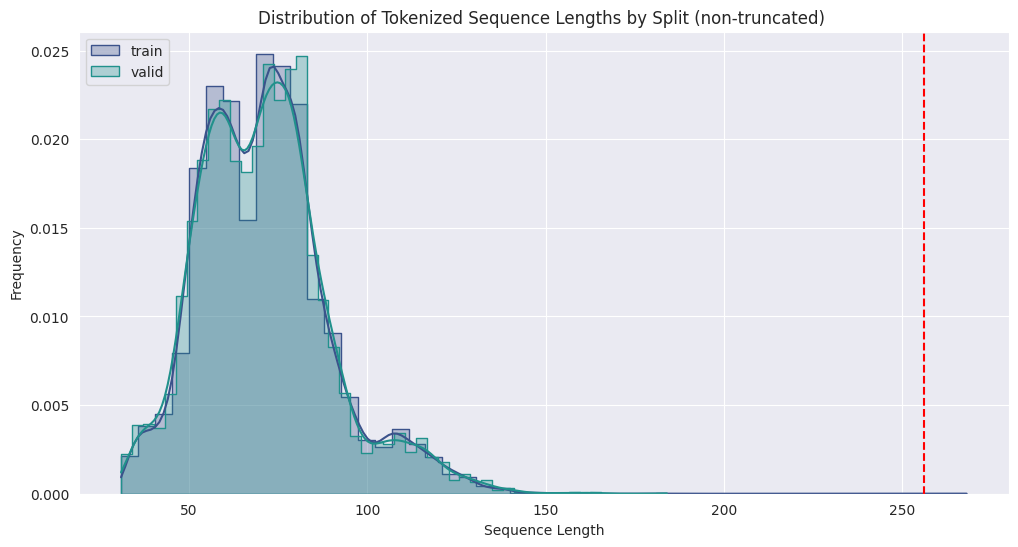

In [18]:
# Create a new figure 
plt.figure(figsize=(12,6))
palette = sns.color_palette(CFG.PALETTE, n_colors=len(hf_dataset))

# Loop through each split and check inputs' length (pre-truncation sets)
for i, split in enumerate(hf_dataset.keys()):
    if split != "test": # skip test because it has only 3 entries
        lengths = [len(tokenizer.encode(t, truncation=False)) for t in hf_dataset[split]["text"]]
        L = (np.array(lengths)>CFG.MAX_LENGTH).sum()
        sns.histplot(lengths, bins=50, label=split, color=palette[i], kde=True, alpha=0.3, stat='density', common_norm=False, element='step')
        
        print(f"There are {L} train sample(s) with more than {CFG.MAX_LENGTH} tokens: {np.sort( lengths )} in {split} split")

# Add labels and legend
plt.axvline(CFG.MAX_LENGTH, linestyle="--",color='red')
plt.xlabel("Sequence Length")
plt.ylabel("Frequency")
plt.title("Distribution of Tokenized Sequence Lengths by Split (non-truncated) ")
plt.legend()
plt.show()

---
## $$WeightedTrainer \ (Trainer \ subclass)$$

> _Why use a weighted trainer?_

This competition’s dataset shows a **strong class imbalance**:  
a few misunderstanding types appear frequently, while others occur only once or twice.

Training without class weights would bias the model toward predicting the most common labels,  
leading to poor recall on rare but important categories.

To address this, we use a **WeightedTrainer**, a modified Hugging Face Trainer that applies  
a class-weighted loss so that underrepresented classes contribute more  
to the gradient updates.

> _Why not use raw weights directly?_

The original class weights span an extreme range (from less than `0.05` up to more than `450`).  
This means that, for the rarest classes, their contribution to the loss would be hundreds of times stronger  
than for common classes. While this seems fair in principle, it often backfires in practice:

- The model may **overfit** to the 1–2 examples of those classes.  
- The gradients can **explode**, causing unstable training or NaNs.  
- The validation loss becomes erratic, and MAP@3 may not improve consistently.

In short, using raw weights directly would make the model “chase” those few examples instead of learning a balanced decision boundary.

> _Why apply weight smoothing (instead of hard capping)?_

We apply a **log-based smoothing transformation** to the normalized weights:

$$
w' = \log(1 + \frac{w}{\bar{w}}) + 1 \\\\\\\\\\\\\\ 
$$[1]

This transformation compresses large weights but preserves their relative importance.  
In contrast, hard capping would simply truncate all extreme values above a fixed threshold,  
potentially erasing meaningful distinctions between moderately rare and ultra-rare classes.

By smoothing instead of capping:
- Training remains numerically stable.  
- Rare classes are still emphasized, just **not overemphasized**.  
- The optimization process becomes more consistent and less noisy.

Thus, **weight smoothing** offers a principled middle ground between ignoring imbalance and  
overcompensating for it.

---

| Aspect | Without Weights | With Raw Weights | With Smoothed Weights |
|---------|----------------|------------------|-----------------------|
| Stability | ✅ Stable | ❌ Unstable (gradient spikes) | ✅ Stable |
| Rare class recall | ❌ Poor | ✅ Very high (but noisy) | ✅ Good and consistent |
| Generalization | ✅ OK | ❌ Overfits rare cases | ✅ Balanced |

[1] _+ 1.0 prevents extremely small weights (< 1) after compression, ensuring the majority class still contributes normally._

---

In [19]:
from torch import nn
from transformers import Trainer
from sklearn.utils.class_weight import compute_class_weight

# Calculate class weights
labels = hf_dataset['train']['label']
class_weights = compute_class_weight(
    class_weight='balanced', 
    classes=np.unique(labels), 
    y=labels
)

# Convert to tensor and normalize to mean = 1
class_weights = torch.tensor(class_weights, dtype=torch.float)
normalized_weights = class_weights / class_weights.mean()

# Smooth: log1p compresses extremes, +1.0 keeps min > 1 to avoid too-small weights
smoothed_weights = torch.log1p(normalized_weights) + 1.0
smoothed_weights = smoothed_weights.to(CFG.DEVICE)

# Subclass Trainer with weighted loss
class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.get("labels")
        outputs = model(**inputs)
        logits = outputs.get("logits")

        # Apply class-weighted CrossEntropy
        loss_fct = nn.CrossEntropyLoss(weight=smoothed_weights)
        loss = loss_fct(logits, labels)
        
        return (loss, outputs) if return_outputs else loss

Unsmoothed class weights range: 0.04 → 451.65
Smoothed class weights range: 1.00 → 2.94


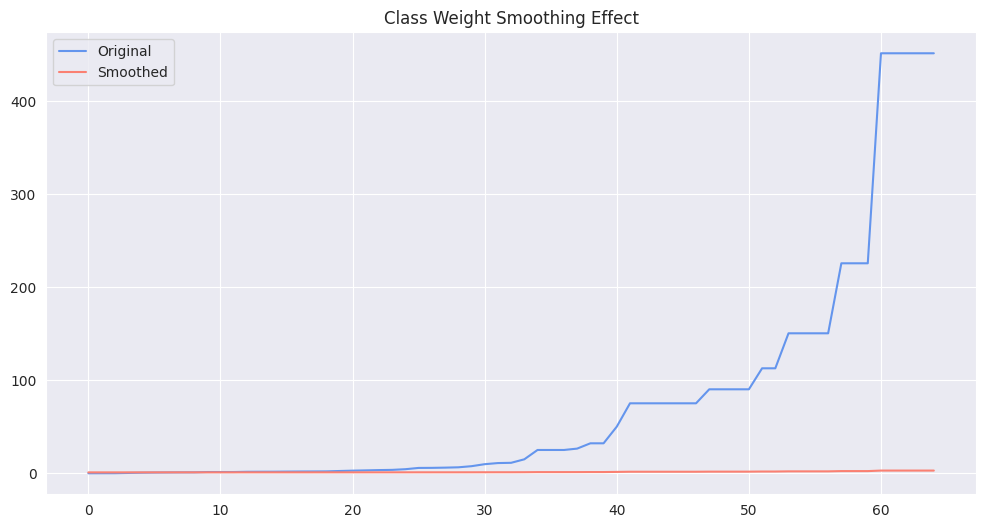

In [20]:
# Weights check (before vs after smoothing)
print(f"Unsmoothed class weights range: {class_weights.min().item():.2f} → {class_weights.max().item():.2f}")
print(f"Smoothed class weights range: {smoothed_weights.min().item():.2f} → {smoothed_weights.max().item():.2f}")

plt.figure(figsize=(12,6))
plt.plot(sorted(class_weights.cpu()),    label='Original', color=CFG.COLOR_1)
plt.plot(sorted(smoothed_weights.cpu()), label='Smoothed', color=CFG.COLOR_2)
plt.legend(); plt.title("Class Weight Smoothing Effect"); plt.show()

* ---
## $$Start \ training$$
model_name = `deberta-v3-large-lora-math-misconceptions-v1`

In [21]:
import os
from transformers import TrainingArguments

# Make directory path
DIR = make_model_dir(
    base_dir       = CFG.BASE_DIRECTORY,
    model_name     = CFG.MODEL_NAME,
    add_version    = True,
    add_timestamp  = False
)

train_args = TrainingArguments(
    output_dir       = f'.{DIR}',
    logging_dir      = f"./{DIR}_logs",
    logging_steps    = 10,
    label_names      = ["labels"],
    eval_strategy    = "epoch",
    save_strategy    = "epoch",
    learning_rate    = 1e-3, #2e-5,
    num_train_epochs = CFG.EPOCHS,
    per_device_train_batch_size = CFG.BATCH_SIZE,
    per_device_eval_batch_size  = CFG.BATCH_SIZE,
    gradient_accumulation_steps = 4,
    warmup_ratio = 0.1, 
    lr_scheduler_type = "linear",
    fp16 = True,                              # mixed precision
    weight_decay  = 0.01,
    max_grad_norm = 1.0,
    seed=CFG.SEED,
    metric_for_best_model  = "map@3",
    load_best_model_at_end = True,
    greater_is_better      = True,
    save_total_limit       = CFG.PATIENCE+1,
    report_to = "none",

    push_to_hub      = CFG.PUSH_TO_HUB,
    hub_token        = CFG.HUGGINGFACE_WRITE_TOKEN if CFG.PUSH_TO_HUB else None,
    hub_model_id     = DIR.split("/")[1],  # or CFG.MODEL_NAME
    hub_private_repo = False,
)

Created directory path: models_for_competitions/deberta-v3-large-LoRA-math-misunderstandings-v1.1


In [22]:
import time

if CFG.TRAINING: 
    summary = {}
    
    # Initialize trainer
    trainer = WeightedTrainer(
    model=lora_model,
    tokenizer=tokenizer,
    data_collator=data_collator,
    args=train_args,
    train_dataset=dataset_encoded["train"],
    eval_dataset=dataset_encoded["valid"],
    compute_metrics=compute_map3,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=CFG.PATIENCE)],
    # optimizers=(optimizer, None) if optimizer is not None else (None, None)
    )

    # Start training
    print("== TRAINING STARTED ==")
    start = time.time()
    if CFG.RESUME_TRAINING:         
        trainer.train(resume_from_checkpoint=CFG.PRETRAINED_CHECKPOINT)
    else:
        trainer.train()
    end = time.time()

    print(f"Training time: {(end - start)/60:.2f} min")

    # Get model info (works with both normal model and LoRA)
    # total, trainable, pct = count_trainable_params(lora_model)
    
    # Get model info with LoRA
    lora_model.print_trainable_parameters()

== TRAINING STARTED ==


/usr/local/lib/python3.11/dist-packages/torch/nn/parallel/_functions.py:70: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.



Epoch,Training Loss,Validation Loss,Map@3
1,1.014400,0.873660,0.824181
2,2.251200,2.250527,0.534610
3,2.264800,2.237438,0.540401
4,2.344100,2.236086,0.540401


/usr/local/lib/python3.11/dist-packages/torch/nn/parallel/_functions.py:70: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.

/usr/local/lib/python3.11/dist-packages/torch/nn/parallel/_functions.py:70: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.

/usr/local/lib/python3.11/dist-packages/torch/nn/parallel/_functions.py:70: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.



Training time: 121.57 min
trainable params: 3,485,761 || all params: 438,340,738 || trainable%: 0.7952


# $$Save \ model$$

In [23]:
# Ensure the adapter weights + config are saved.
if CFG.TRAINING:
    if CFG.SAVE_LOCALLY:
        lora_model.save_pretrained(f'./{DIR}_best_model')
        tokenizer.save_pretrained(f'./{DIR}_best_model')
        try: 
            lora_model.config.save_pretrained(f'./{DIR}_best_model')
        except Exception as e:
            print(f"error, {e}")

        print(f"Model saved in {DIR}_best_model")
    
    if CFG.PUSH_TO_HUB:
        trainer.push_to_hub(train_args.hub_model_id,token=CFG.HUGGINGFACE_WRITE_TOKEN)
        try:
            lora_model.config.push_to_hub(train_args.hub_model_id, token=CFG.HUGGINGFACE_WRITE_TOKEN)
        except Exception as e:
            print(f"error, {e}")
        print(f"Model pushed to hub as {DIR.split('/')[1]}")

Model saved in models_for_competitions/deberta-v3-large-LoRA-math-misunderstandings-v1.1_best_model


Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

README.md: 0.00B [00:00, ?B/s]

Model pushed to hub as deberta-v3-large-LoRA-math-misunderstandings-v1.1


# $$Load \ model \ and  \ predict \ test$$ 

In [24]:
from peft import AutoPeftModelForSequenceClassification, PeftConfig
from transformers import AutoTokenizer, DataCollatorWithPadding

if CFG.USE_FINE_TUNED:
    # Load PEFT config (contains base model path)
    hub_model = f"{CFG.REPO_ID}/{DIR.split('/')[1]}"
    peft_config = PeftConfig.from_pretrained(
        hub_model,
        token=CFG.HUGGINGFACE_READ_TOKEN
    )

    # Load the full model (base + adapter)
    finetuned_model = AutoPeftModelForSequenceClassification.from_pretrained(
        hub_model,
        token=CFG.HUGGINGFACE_READ_TOKEN,

        # Apparently we still need to report the id2label and label2id even though
        # those metadata are stored in the finetuned LoRA repo (https://huggingface.co/Francesco-A/deberta-v3-large-LoRA-math-misunderstandings-v1/blob/main/config.json)
        num_labels=len(le.classes_),
        id2label=id2label,
        label2id=label2id
    )
    # finetuned_model.eval()
    finetuned_model.to(CFG.DEVICE)

    # Load tokenizer from *base model*, not adapter
    tokenizer = AutoTokenizer.from_pretrained(peft_config.base_model_name_or_path) # CFG.CHECKPOINT
    
    # Data collator (same as training)
    data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
    
    # Dummy trainer for inference utilities
    inference_args = TrainingArguments(
        report_to="none",
        fp16=True,
        per_device_eval_batch_size=CFG.BATCH_SIZE,
        label_names=["labels"],
    )
    
    inference_trainer = WeightedTrainer(
        model=finetuned_model,
        tokenizer=tokenizer,
        data_collator=data_collator,
        args=inference_args,
    )
    
    print("✅ LoRA model loaded successfully")

In [25]:
ds_test = Dataset.from_pandas(TEST_DF[['text']])
ds_test = ds_test.map(tokenize, batched=True)

if CFG.USE_FINE_TUNED:
    predictions = inference_trainer.predict(ds_test)
else:
    predictions = trainer.predict(ds_test)

probs = torch.nn.functional.softmax(torch.tensor(predictions.predictions), dim=1).numpy()

Map:   0%|          | 0/3 [00:00<?, ? examples/s]

In [26]:
# # ===== REFERENCE CODE: Get predictions without using a dummy Trainer =====

# from tqdm import tqdm
# from torch.nn.functional import softmax

# # You can batch for efficiency
# batch_size = CFG.BATCH_SIZE

# all_probs = []
# for i in tqdm(range(0, len(TEST_DF), batch_size)):
#     batch_texts = TEST_DF.text.iloc[i:i+batch_size].tolist()

#     # Tokenize
#     encodings = tokenizer(
#         batch_texts,
#         padding=True,
#         truncation=True,
#         return_tensors="pt",
#         max_length=CFG.MAX_LENGTH,
#     ).to(CFG.DEVICE)

#     # Forward pass
#     with torch.no_grad():
#         outputs = finetuned_model(**encodings)
#         logits = outputs.logits  # shape: [batch_size, num_labels]
#         probs = softmax(logits, dim=-1).cpu().numpy()  # convert to numpy for sorting

#     all_probs.append(probs)

# # Concatenate all batches
# probs = np.concatenate(all_probs, axis=0)
# print("✅ Probabilities shape:", probs.shape)

# $$Submission \ CSV$$

In [27]:
# Get top 3 predicted class indices
top3 = np.argsort(-probs, axis=1)[:, :3]   # shape: [num_samples, 3]

# Decode numeric class indices to original string labels 
flat_top3 = top3.flatten()
decoded_labels = le.inverse_transform(flat_top3)
top3_labels = decoded_labels.reshape(top3.shape)

# Join 3 labels per row with space
joined_preds = [" ".join(row) for row in top3_labels]

# Save submission
sub = pd.DataFrame({
    "row_id": TEST_DF.row_id.values,
    "Category:Misconception": joined_preds
})
sub.to_csv("submission.csv", index=False)
sub.head()

,row_id,Category:Misconception
0,36696,True_Correct:NA True_Neither:NA True_Misconcep...
1,36697,False_Misconception:Incomplete False_Neither:N...
2,36698,True_Correct:NA True_Neither:NA True_Misconcep...
